In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score
from os import pipe
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score

np.random.seed(42)
print("✅ Libraries imported successfully!")
print(f"NumPy version: {np.__version__}")

✅ Libraries imported successfully!
NumPy version: 2.0.2


In [ ]:
dset = fetch_openml('mnist_784', version=1)
X = dset['data']
y = dset['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train_temp = X_train #for the graph in step 3
y_train_temp = y_train #for the graph in step 3

X_train = X_train / 255.0
X_test = X_test / 255.0

X_train = X_train.values.T
X_test = X_test.values.T
y_train = y_train.values.T
y_test = y_test.values.T
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (784, 56000)
y_train shape: (56000,)
X_test shape: (784, 14000)
y_test shape: (14000,)


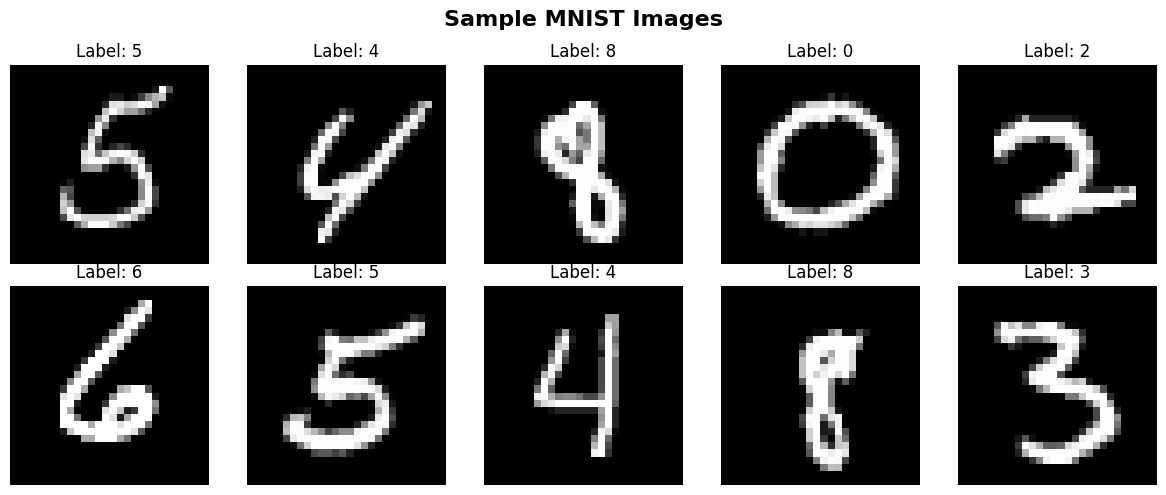

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train_temp.iloc[i].values.reshape(28, 28), cmap='gray')
    ax.set_title(f'Label: {y_train_temp.iloc[i]}')
    ax.axis('off')
plt.suptitle('Sample MNIST Images', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
def relu(z):
  return np.maximum(0, z)

def softmax(z):
  exp_z = np.exp(z - np.max(z, axis=0, keepdims=True))
  return exp_z / np.sum(exp_z, axis=0, keepdims=True)

def relu_derivative(z):
  return (z > 0).astype(float)

In [ ]:
#one hot encoding

def one_hot_encode(y, num_classes=10):

  if isinstance(y, pd.Series):
    y = y.values

  one_hot_y = np.zeros((num_classes, y.size))
  one_hot_y[y.astype(int), np.arange(y.size)] = 1

  return one_hot_y


In [ ]:
def initialize_parameters(input_size, hidden_size, output_size):
  # TODO
  W1 = np.random.randn(hidden_size, input_size) * 0.01
  b1 = np.zeros((hidden_size, 1))
  W2 = np.random.randn(output_size, hidden_size) * 0.01
  b2 = np.zeros((output_size, 1))

  parameters = {
    "W1": W1,
    "b1": b1,
    "W2": W2,
    "b2": b2
  }

  return parameters

In [ ]:
#forward propagation

def forward_propagation(X, parameters):
  # TODO
  W1 = parameters["W1"]
  b1 = parameters["b1"]
  W2 = parameters["W2"]
  b2 = parameters["b2"]

  Z1 = np.dot(W1, X) + b1
  A1 = relu(Z1)
  Z2 = np.dot(W2, A1) + b2
  A2 = softmax(Z2)

  cache = {
    "Z1": Z1,
    "A1": A1,
    "Z2": Z2,
    "A2": A2
  }
  return cache


In [ ]:
#loss func

def compute_loss(y_true, y_pred):
  epsilon = 1e-15
  y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

  y_true = np.array(y_true)
  loss = -np.mean(y_true * np.log(y_pred))


  return loss

In [ ]:
#backprop

def backward_propagation(X, y_true, cache, parameters):
  W1 = parameters["W1"]
  W2 = parameters["W2"]

  m = X.shape[1]

  A1 = cache["A1"]
  A2 = cache["A2"]
  Z1 = cache["Z1"]

  dZ2 = A2 - y_true
  dW2 = (1 / m) * np.dot(dZ2, A1.T)
  db2 = (1 / m) * np.sum(dZ2, axis=1, keepdims=True)

  dZ1 = np.dot(W2.T, dZ2) * relu_derivative(Z1) #gradient descent of the loss function
  dW1 = (1 / m) * np.dot(dZ1, X.T)
  db1 = (1 / m) * np.sum(dZ1, axis=1, keepdims=True)

  return {
    "dW1": dW1,
    "db1": db1,
    "dW2": dW2,
    "db2": db2
  }

In [ ]:

def update_parameters(parameters, gradients, learning_rate):
  new_parameters = {}
  new_parameters["W1"] = parameters["W1"] - learning_rate * gradients["dW1"]
  new_parameters["b1"] = parameters["b1"] - learning_rate * gradients["db1"]
  new_parameters["W2"] = parameters["W2"] - learning_rate * gradients["dW2"]
  new_parameters["b2"] = parameters["b2"] - learning_rate * gradients["db2"]

  return new_parameters

In [ ]:
#training function

def train_neural_network(X_train, y_train, X_val, y_val,
                         hidden_size=128, learning_rate=0.1,
                         epochs=20, batch_size=32, verbose=True):
    input_size = X_train.shape[0]
    output_size = 10

    parameters = initialize_parameters(input_size, hidden_size, output_size)
    train_losses = []
    train_accuracies = []
    val_losses = []
    val_accuracies = []

    y_train_one_hot = one_hot_encode(y_train, num_classes=output_size)
    y_val_one_hot = one_hot_encode(y_val, num_classes=output_size)


    for epoch in range(epochs):

        cache = forward_propagation(X_train, parameters)

        loss = compute_loss(y_train_one_hot, cache["A2"])
        train_losses.append(loss)

        train_predictions = np.argmax(cache["A2"], axis=0)
        train_accuracy = accuracy_score(y_train, train_predictions)
        train_accuracies.append(train_accuracy)

        gradients = backward_propagation(X_train, y_train_one_hot, cache, parameters)
        parameters = update_parameters(parameters, gradients, learning_rate)

        val_cache = forward_propagation(X_val, parameters)
        val_loss = compute_loss(y_val_one_hot, val_cache["A2"])
        val_losses.append(val_loss)

        val_predictions = np.argmax(val_cache["A2"], axis=0)
        val_accuracy = accuracy_score(y_val, val_predictions)
        val_accuracies.append(val_accuracy)


    return parameters, train_losses, train_accuracies, val_losses, val_accuracies

In [ ]:
#train

history = {
    'train_loss': [],
    'val_loss': [],
    'train_acc': [],
    'val_acc': []
}

parameters, losses, accuracies, val_loss, val_acc = train_neural_network(X_train, y_train, X_test, y_test, hidden_size=128, learning_rate=0.1, epochs=20, batch_size=128, verbose=True)

history['train_loss'] = losses
history['train_acc'] = accuracies
history['val_loss'] = val_loss
history['val_acc'] = val_acc

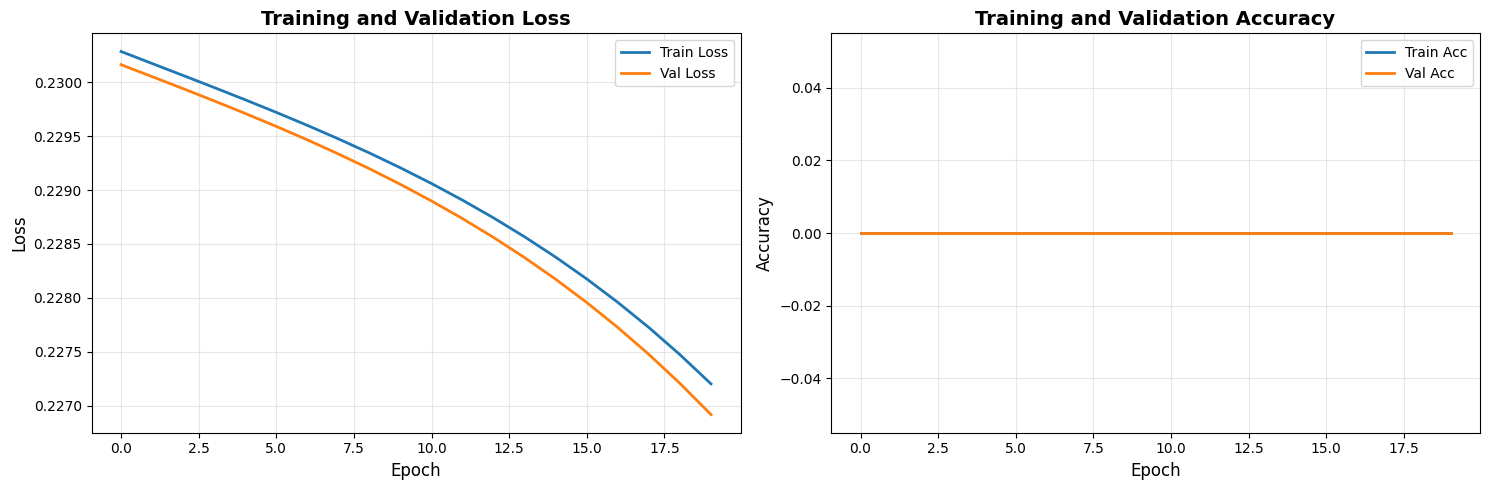

Final Train Accuracy: 0.0000
Final Val Accuracy: 0.0000


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(history['train_loss'], label='Train Loss', linewidth=2)
axes[0].plot(history['val_loss'], label='Val Loss', linewidth=2)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Loss', fontsize=12)
axes[0].set_title('Training and Validation Loss', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history['train_acc'], label='Train Acc', linewidth=2)
axes[1].plot(history['val_acc'], label='Val Acc', linewidth=2)
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Accuracy', fontsize=12)
axes[1].set_title('Training and Validation Accuracy', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Final Train Accuracy: {history['train_acc'][-1]:.4f}")
print(f"Final Val Accuracy: {history['val_acc'][-1]:.4f}")

(784, 14000)
(128, 784)
(128, 1)
Test Accuracy: 0.0000

Classification Report:
              precision    recall  f1-score   support

           0       0.36      0.98      0.53      1343
           1       0.95      0.79      0.86      1600
           2       0.30      0.89      0.45      1380
           3       0.76      0.57      0.65      1433
           4       0.91      0.07      0.13      1295
           5       0.00      0.00      0.00      1273
           6       0.88      0.50      0.64      1396
           7       0.65      0.73      0.69      1503
           8       0.84      0.39      0.53      1357
           9       0.69      0.35      0.46      1420

    accuracy                           0.54     14000
   macro avg       0.64      0.53      0.50     14000
weighted avg       0.64      0.54      0.51     14000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


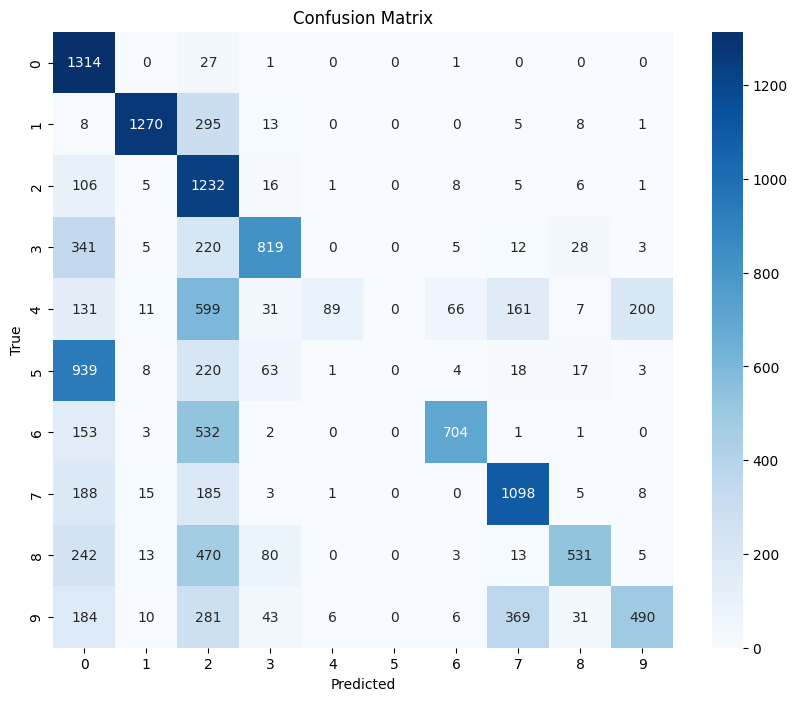

In [ ]:
#eval

test_cache = forward_propagation(X_test, parameters)
test_predictions = np.argmax(test_cache["A2"], axis=0)

#test accuracy
test_accuracy = accuracy_score(y_test, test_predictions)
print(f"Test Accuracy: {test_accuracy:.4f}")

#classification report
print("\nClassification Report:")
print(classification_report(y_test.astype(int), test_predictions))

#confusion matrix
cm = confusion_matrix(y_test.astype(int), test_predictions)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

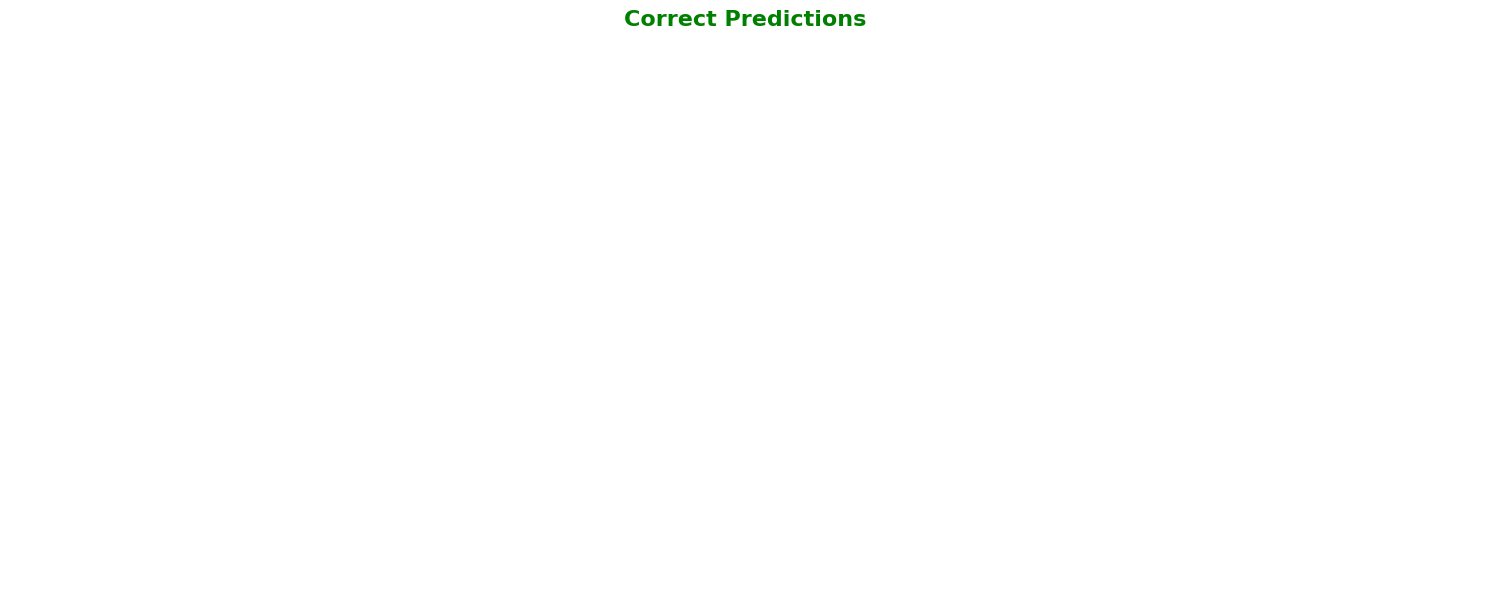

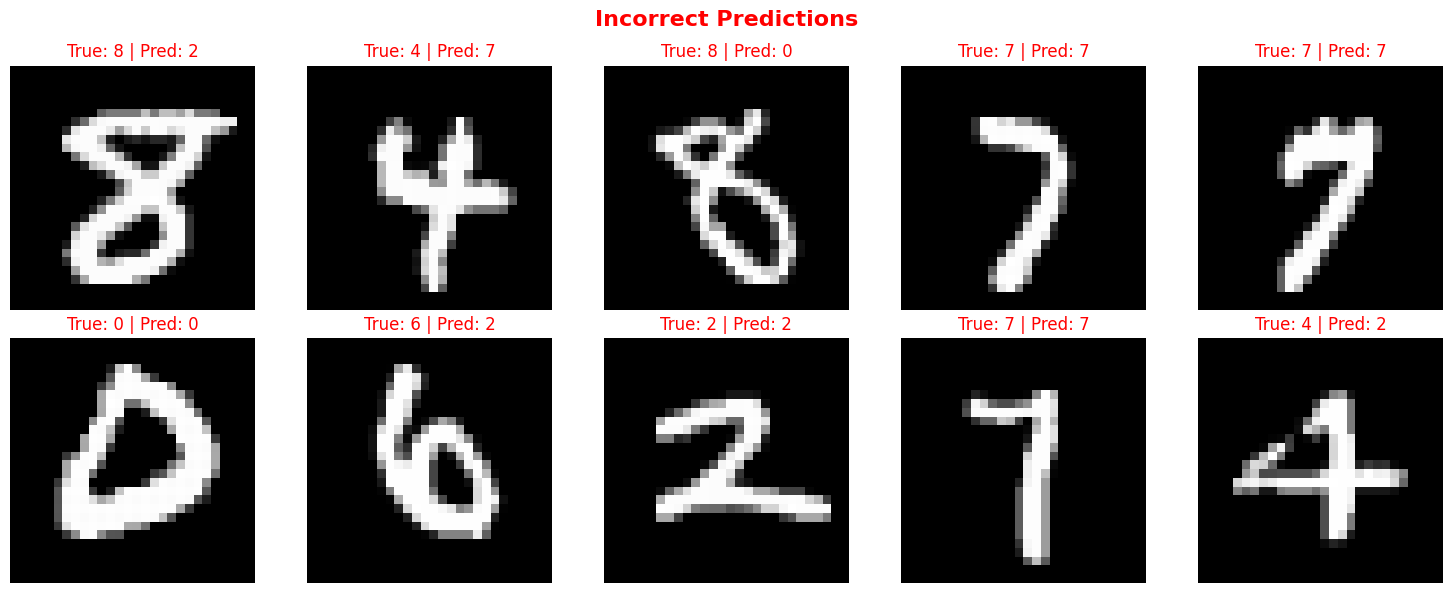

In [ ]:
X_test_display = X_test.T


correct_idx = np.where(test_predictions == y_test.to_numpy())[0]
incorrect_idx = np.where(test_predictions != y_test.to_numpy())[0]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle('Correct Predictions', fontsize=16, fontweight='bold', color='green')
for i, ax in enumerate(axes.flat):
    if i < len(correct_idx):
        idx = correct_idx[i]
        ax.imshow(X_test_display[int(idx)].reshape(28, 28), cmap='gray')
        ax.set_title(f'True: {y_test.to_numpy()[int(idx)]} | Pred: {test_predictions[int(idx)]}', color='green')
        ax.axis('off')
    else:
        ax.axis('off')
plt.tight_layout()
plt.show()

if len(incorrect_idx) > 0:
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    fig.suptitle('Incorrect Predictions', fontsize=16, fontweight='bold', color='red')
    for i, ax in enumerate(axes.flat):
        if i < len(incorrect_idx):
            idx = incorrect_idx[i]
            ax.imshow(X_test_display[int(idx)].reshape(28, 28), cmap='gray')
            ax.set_title(f'True: {y_test.to_numpy()[int(idx)]} | Pred: {test_predictions[int(idx)]}', color='red')
            ax.axis('off')
        else:
            ax.axis('off')
    plt.tight_layout()
    plt.show()